# Topic 2: Matrices

## Learning Objectives

By the end of this topic, I will be able to:

1. Represent matrices using mathematical notation and NumPy arrays.
2. Identify matrix dimensions, rows, columns, and shape.
3. Perform matrix operations using pure Python and NumPy.
4. Visualize matrix values using Matplotlib.
5. Understand how matrices represent linear transformations.
6. Apply matrix operations to Machine Learning problems.

## Mathematical Definition

A matrix is a rectangular arrangement of numbers organized into
rows and columns.

A matrix with `m` rows and `n` columns has shape `(m, n)`.

We write its dimensions as `m × n`.

In [2]:
import numpy as np

# Create a matrix using a Python nested list
matrix = [
    [1, 2, 3],
    [4, 5, 6]
]

# Convert the list into a NumPy array
matrix_np = np.array(matrix)

print("Matrix:")
print(matrix_np)

print("Shape:", matrix_np.shape)
print("Number of dimensions:", matrix_np.ndim)
print("Total elements:", matrix_np.size)
print("Number of rows:", matrix_np.shape[0])
print("Number of columns:", matrix_np.shape[1])

Matrix:
[[1 2 3]
 [4 5 6]]
Shape: (2, 3)
Number of dimensions: 2
Total elements: 6
Number of rows: 2
Number of columns: 3


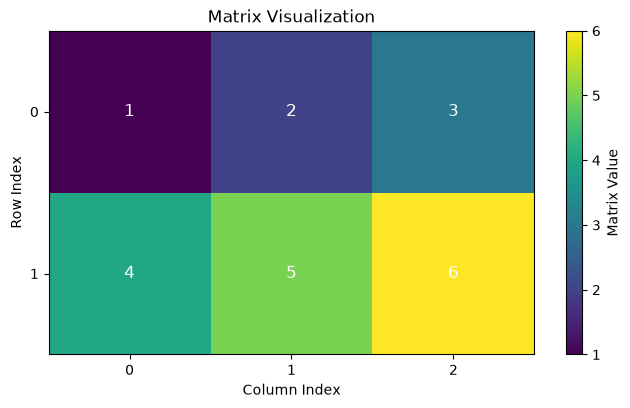

In [6]:

import matplotlib.pyplot as plt
import numpy as np

matrix_np = np.array([
    [1, 2, 3],
    [4, 5, 6]
])

fig, ax = plt.subplots(figsize=(7, 4))

image = ax.imshow(matrix_np, cmap="viridis")

# Label the rows and columns
ax.set_xticks(range(matrix_np.shape[1]))
ax.set_yticks(range(matrix_np.shape[0]))

ax.set_xlabel("Column Index")
ax.set_ylabel("Row Index")
ax.set_title("Matrix Visualization")

# Display each matrix value inside its cell
for i in range(matrix_np.shape[0]):
    for j in range(matrix_np.shape[1]):
        ax.text(
            j, i,
            str(matrix_np[i, j]),
            ha="center",
            va="center",
            color="white",
            fontsize=12
        )

fig.colorbar(image, ax=ax, label="Matrix Value")
fig.tight_layout()
plt.show()


## 2. Matrix Indexing and Slicing

NumPy uses zero-based indexing to access matrix elements.

For a matrix A:
- `A[i, j]` accesses the element at row `i`, column `j`.
- `A[i, :]` selects the complete row `i`.
- `A[:, j]` selects the complete column `j`.
- `A[r1:r2, c1:c2]` selects a submatrix using slices.

The starting index of a slice is included, but the ending
index is excluded.

Indexing helps us access individual values, while slicing
allows us to select larger portions of a matrix.

In [7]:
import numpy as np

A = np.array([
    [1, 2, 3],
    [4, 5, 6],
    [7, 8, 9]
])

print("Complete matrix:\n", A)

# Access one element
print("Element at row 1, column 2:", A[1, 2])

# Access a complete row
print("Second row:", A[1, :])

# Access a complete column
print("Second column:", A[:, 1])

# Extract a submatrix
print("Submatrix:\n", A[0:2, 1:3])

Complete matrix:
 [[1 2 3]
 [4 5 6]
 [7 8 9]]
Element at row 1, column 2: 6
Second row: [4 5 6]
Second column: [2 5 8]
Submatrix:
 [[2 3]
 [5 6]]


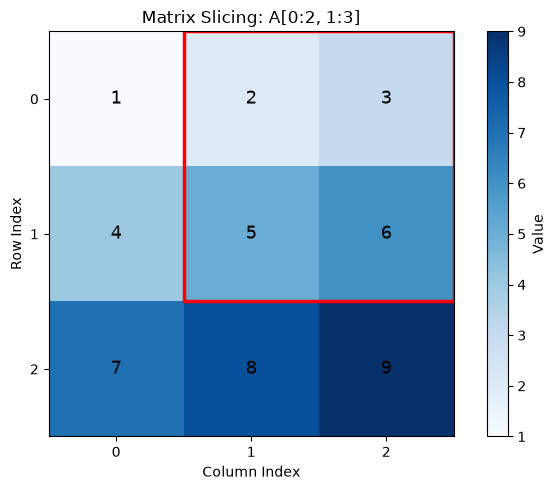

In [8]:

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

fig, ax = plt.subplots(figsize=(7, 5))

image = ax.imshow(A, cmap="Blues")

# Display each element
for i in range(A.shape[0]):
    for j in range(A.shape[1]):
        ax.text(
            j, i, str(A[i, j]),
            ha="center",
            va="center",
            color="black",
            fontsize=13
        )

# Highlight A[0:2, 1:3]
highlight = Rectangle(
    (0.5, -0.5),
    2,
    2,
    fill=False,
    edgecolor="red",
    linewidth=2.5
)
ax.add_patch(highlight)

ax.set_xticks(range(A.shape[1]))
ax.set_yticks(range(A.shape[0]))
ax.set_xlabel("Column Index")
ax.set_ylabel("Row Index")
ax.set_title("Matrix Slicing: A[0:2, 1:3]")

fig.colorbar(image, ax=ax, label="Value")
fig.tight_layout()
plt.show()


## 3. Matrix Addition and Subtraction

Matrix addition and subtraction operate on corresponding elements
of two matrices.

For these operations, both matrices must have the same shape.

### Matrix Addition

If A and B have the same shape, their sum is defined as:

(A + B)[i, j] = A[i, j] + B[i, j]

### Matrix Subtraction

Their difference is defined as:

(A - B)[i, j] = A[i, j] - B[i, j]

### Important Rule

If A has shape (m, n), then B must also have shape (m, n).
Otherwise, standard matrix addition and subtraction are undefined.

NumPy supports element-wise addition and subtraction using `+` and `-`.

In Machine Learning, these operations are used in data processing,
weight updates, residual calculations, and numerical algorithms.

In [9]:

def add_matrices_python(A, B):
    """Add two matrices using pure Python."""
    if len(A) != len(B) or any(
        len(row_a) != len(row_b)
        for row_a, row_b in zip(A, B)
    ):
        raise ValueError("Matrices must have the same shape.")

    return [
        [x + y for x, y in zip(row_a, row_b)]
        for row_a, row_b in zip(A, B)
    ]


def subtract_matrices_python(A, B):
    """Subtract B from A using pure Python."""
    if len(A) != len(B) or any(
        len(row_a) != len(row_b)
        for row_a, row_b in zip(A, B)
    ):
        raise ValueError("Matrices must have the same shape.")

    return [
        [x - y for x, y in zip(row_a, row_b)]
        for row_a, row_b in zip(A, B)
    ]


# Define two matrices
matrix_a_list = [
    [1, 2, 3],
    [4, 5, 6]
]

matrix_b_list = [
    [6, 5, 4],
    [3, 2, 1]
]

# Calculate results
addition_python = add_matrices_python(
    matrix_a_list, matrix_b_list
)

subtraction_python = subtract_matrices_python(
    matrix_a_list, matrix_b_list
)

print("Addition:", addition_python)
print("Subtraction:", subtraction_python)


Addition: [[7, 7, 7], [7, 7, 7]]
Subtraction: [[-5, -3, -1], [1, 3, 5]]


In [10]:

import numpy as np

matrix_a = np.array(matrix_a_list)
matrix_b = np.array(matrix_b_list)

addition_numpy = matrix_a + matrix_b
subtraction_numpy = matrix_a - matrix_b

print("Matrix A shape:", matrix_a.shape)
print("Matrix B shape:", matrix_b.shape)

print("\nNumPy addition:\n", addition_numpy)
print("\nNumPy subtraction:\n", subtraction_numpy)

print("\n--- Verification ---")
print(
    "Addition matches:",
    np.array_equal(addition_numpy, addition_python)
)
print(
    "Subtraction matches:",
    np.array_equal(subtraction_numpy, subtraction_python)
)


Matrix A shape: (2, 3)
Matrix B shape: (2, 3)

NumPy addition:
 [[7 7 7]
 [7 7 7]]

NumPy subtraction:
 [[-5 -3 -1]
 [ 1  3  5]]

--- Verification ---
Addition matches: True
Subtraction matches: True


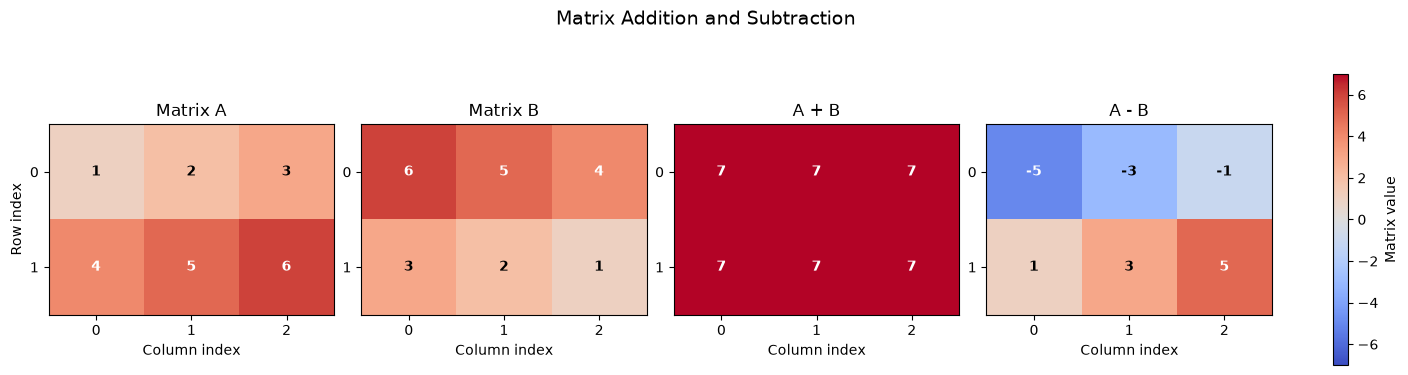

In [11]:

import matplotlib.pyplot as plt
import numpy as np

matrices = [
    matrix_a,
    matrix_b,
    addition_numpy,
    subtraction_numpy,
]

titles = [
    "Matrix A",
    "Matrix B",
    "A + B",
    "A - B",
]

# Use a common colour scale for fair visual comparison
limit = max(float(np.abs(M).max()) for M in matrices)

fig, axes = plt.subplots(
    1, 4,
    figsize=(14, 4),
    constrained_layout=True,
)

for ax, M, title in zip(axes, matrices, titles):
    image = ax.imshow(
        M,
        cmap="coolwarm",
        vmin=-limit,
        vmax=limit,
    )

    # Annotate every matrix element
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            value = M[i, j]
            text_color = (
                "white" if abs(value) > limit * 0.55
                else "black"
            )

            ax.text(
                j, i, str(value),
                ha="center",
                va="center",
                color=text_color,
                fontweight="bold",
            )

    ax.set_title(title)
    ax.set_xlabel("Column index")
    ax.set_xticks(range(M.shape[1]))
    ax.set_yticks(range(M.shape[0]))

axes[0].set_ylabel("Row index")

fig.colorbar(
    image,
    ax=axes,
    shrink=0.8,
    label="Matrix value",
)

fig.suptitle("Matrix Addition and Subtraction", fontsize=14)
plt.show()


## 4. Scalar Multiplication of Matrices

Scalar multiplication means multiplying every element of a matrix
by the same scalar value.

If A is a matrix and c is a scalar, then:

(cA)[i, j] = c * A[i, j]

For example:

A = [[1, 2],
     [3, 4]]

If c = 2:

2A = [[2, 4],
      [6, 8]]

If c = -1:

-A = [[-1, -2],
      [-3, -4]]

### Important Properties

1. Every element is multiplied by the scalar.
2. The shape of the matrix does not change.
3. Multiplying by 1 preserves the matrix.
4. Multiplying by 0 produces a zero matrix.
5. Multiplying by a negative scalar reverses the signs of all
   non-zero elements.

Scalar multiplication is used in matrix transformations,
numerical algorithms, and machine-learning computations.

In [12]:

def scale_matrix_python(scalar, matrix):
    """Multiply every matrix element by a scalar using pure Python."""

    return [
        [scalar * element for element in row]
        for row in matrix
    ]


# Use the matrix created in the previous section
matrix_a_list = [
    [1, 2, 3],
    [4, 5, 6]
]

scalar = 2

scaled_matrix_python = scale_matrix_python(
    scalar, matrix_a_list
)

print("Original matrix:", matrix_a_list)
print("Scalar:", scalar)
print("Scaled matrix:", scaled_matrix_python)


Original matrix: [[1, 2, 3], [4, 5, 6]]
Scalar: 2
Scaled matrix: [[2, 4, 6], [8, 10, 12]]


In [13]:

import numpy as np

matrix_a = np.array(matrix_a_list)
scalar = 2

scaled_matrix_numpy = scalar * matrix_a

print("Original matrix:\n", matrix_a)
print("\nScaled matrix:\n", scaled_matrix_numpy)
print("\nOriginal shape:", matrix_a.shape)
print("Scaled shape:", scaled_matrix_numpy.shape)

print(
    "\nResults match:",
    np.array_equal(
        scaled_matrix_numpy,
        scaled_matrix_python
    )
)


Original matrix:
 [[1 2 3]
 [4 5 6]]

Scaled matrix:
 [[ 2  4  6]
 [ 8 10 12]]

Original shape: (2, 3)
Scaled shape: (2, 3)

Results match: True


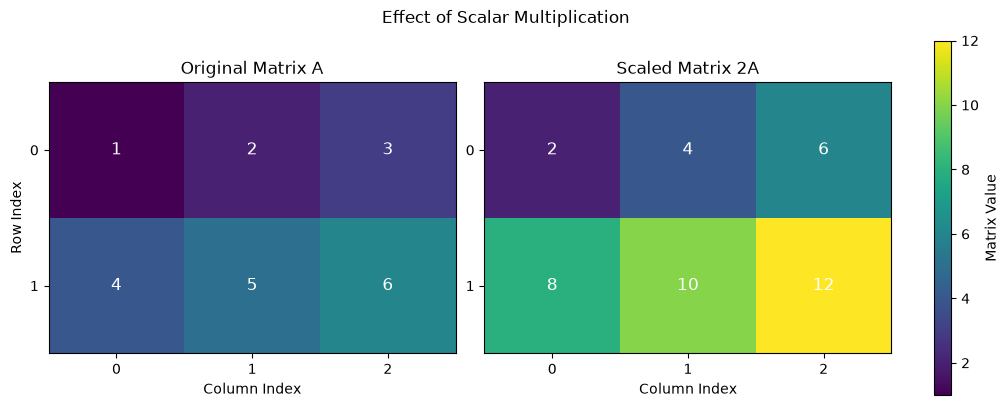

In [14]:

import matplotlib.pyplot as plt
import numpy as np

matrices = [
    matrix_a,
    scaled_matrix_numpy
]

titles = [
    "Original Matrix A",
    "Scaled Matrix 2A"
]

# Keep the same colour scale for a fair comparison
vmin = min(float(M.min()) for M in matrices)
vmax = max(float(M.max()) for M in matrices)

fig, axes = plt.subplots(
    1, 2,
    figsize=(10, 4),
    constrained_layout=True
)

for ax, M, title in zip(axes, matrices, titles):
    image = ax.imshow(
        M,
        cmap="viridis",
        vmin=vmin,
        vmax=vmax
    )

    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(
                j, i,
                str(M[i, j]),
                ha="center",
                va="center",
                color="white",
                fontsize=12
            )

    ax.set_title(title)
    ax.set_xlabel("Column Index")
    ax.set_xticks(range(M.shape[1]))
    ax.set_yticks(range(M.shape[0]))

axes[0].set_ylabel("Row Index")

fig.colorbar(
    image,
    ax=axes,
    label="Matrix Value"
)

fig.suptitle("Effect of Scalar Multiplication")
plt.show()


Negative scalar multiplication:
 [[-1 -2 -3]
 [-4 -5 -6]]


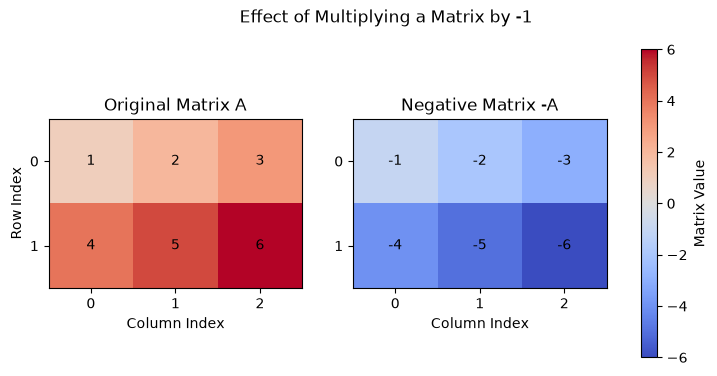

In [15]:
negative_scaled_matrix = -1 * matrix_a

print("Negative scalar multiplication:\n", negative_scaled_matrix)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))

images = [
    axes[0].imshow(matrix_a, cmap="coolwarm", vmin=-6, vmax=6),
    axes[1].imshow(negative_scaled_matrix, cmap="coolwarm", vmin=-6, vmax=6)
]

axes[0].set_title("Original Matrix A")
axes[1].set_title("Negative Matrix -A")

for ax, M in zip(axes, [matrix_a, negative_scaled_matrix]):
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, str(M[i, j]), ha="center", va="center", color="black")

    ax.set_xticks(range(M.shape[1]))
    ax.set_yticks(range(M.shape[0]))
    ax.set_xlabel("Column Index")

axes[0].set_ylabel("Row Index")
fig.colorbar(images[0], ax=axes, label="Matrix Value")
fig.suptitle("Effect of Multiplying a Matrix by -1")
plt.show()

## 5. Matrix Transpose

### 5.1 Definition

The transpose of a matrix is obtained by interchanging its rows
and columns. The transpose of a matrix A is denoted by A^T.

Every element at position (i, j) in the original matrix moves
to position (j, i) in the transposed matrix.

### 5.2 Mathematical Notation

For a matrix A with m rows and n columns:

$$
A \in \mathbb{R}^{m \times n}
$$

Its transpose is:

$$
A^T \in \mathbb{R}^{n \times m}
$$

The element-wise rule is:

$$
(A^T)_{ij} = A_{ji}
$$

Therefore, transposition swaps the row and column indices
and reverses the shape of the matrix.

### 5.3 Worked Example

Consider the matrix:

$$
A =
\begin{bmatrix}
1 & 2 & 3 \\
4 & 5 & 6
\end{bmatrix}
$$

Matrix A has 2 rows and 3 columns, so its shape is (2, 3).

After transposition:

$$
A^T =
\begin{bmatrix}
1 & 4 \\
2 & 5 \\
3 & 6
\end{bmatrix}
$$

The transposed matrix has 3 rows and 2 columns, so its shape is (3, 2).

Notice that the first row of A becomes the first column of A^T,
and the second row of A becomes the second column of A^T.

### 5.4 Important Properties

1. Transposing a matrix twice returns the original matrix.

   $$
   (A^T)^T = A
   $$

2. The transpose of a sum equals the sum of the transposes.

   $$
   (A + B)^T = A^T + B^T
   $$

3. The transpose of a scalar multiple preserves the scalar.

   $$
   (cA)^T = cA^T
   $$

4. Transposition reverses the order of matrix multiplication.

   $$
   (AB)^T = B^T A^T
   $$

   This identity applies when the matrix product AB is defined.

### 5.5 Applications in Machine Learning

Matrix transposition is used in linear algebra calculations,
least-squares regression, covariance calculations, and
machine-learning model implementations.

For example, transposition helps arrange feature data into
the orientation required by a mathematical operation.

### 5.6 Common Mistakes

- Confusing transpose with inverse. They are different operations.
- Assuming that transposition changes the matrix values. It changes
  their positions, not their numerical values.
- Forgetting that the number of rows and columns is swapped.
- Confusing a one-dimensional NumPy array with a row or column matrix.

### Learning Outcome

After this section, I should be able to calculate a matrix transpose
manually, implement it using pure Python, verify it using NumPy,
visualize the transformation, and explain its mathematical properties.

In [16]:

def transpose_matrix_python(matrix):
    """Transpose a rectangular matrix using pure Python."""

    if not matrix or not matrix[0]:
        raise ValueError("Matrix must have at least one row and column.")

    column_count = len(matrix[0])

    if any(len(row) != column_count for row in matrix):
        raise ValueError("Matrix must be rectangular.")

    return [
        [matrix[row][col] for row in range(len(matrix))]
        for col in range(column_count)
    ]


# Define a 2 x 3 matrix
A_list = [
    [1, 2, 3],
    [4, 5, 6]
]

A_transpose_python = transpose_matrix_python(A_list)

print("Original matrix:")
print(A_list)

print("\nTransposed matrix:")
print(A_transpose_python)


Original matrix:
[[1, 2, 3], [4, 5, 6]]

Transposed matrix:
[[1, 4], [2, 5], [3, 6]]


In [17]:
import numpy as np

A = np.array(A_list)

A_transpose_numpy = A.T

print("Original shape:", A.shape)
print("Transpose shape:", A_transpose_numpy.shape)

print("\nNumPy transpose:")
print(A_transpose_numpy)

print(
    "\nPython an NumPy results match:",
    np.array_equal(A_transpose_python, A_transpose_numpy)
)

print(
    "Double transpose returns original:",
    np.array_equal(A_transpose_numpy.T, A)
)

Original shape: (2, 3)
Transpose shape: (3, 2)

NumPy transpose:
[[1 4]
 [2 5]
 [3 6]]

Python an NumPy results match: True
Double transpose returns original: True


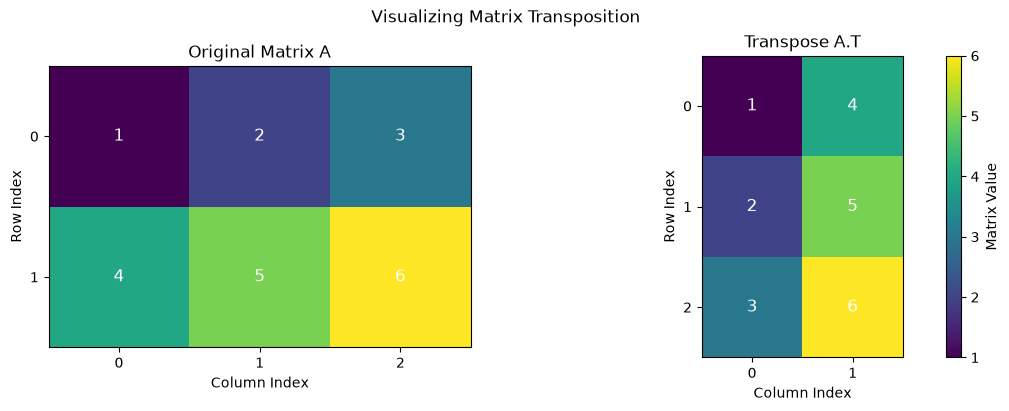

In [18]:

import matplotlib.pyplot as plt
import numpy as np

matrices = [A, A_transpose_numpy]
titles = ["Original Matrix A", "Transpose A.T"]

# Use a common colour scale for both matrices
vmin = min(float(M.min()) for M in matrices)
vmax = max(float(M.max()) for M in matrices)

fig, axes = plt.subplots(
    1, 2,
    figsize=(10, 4),
    constrained_layout=True
)

for ax, M, title in zip(axes, matrices, titles):
    image = ax.imshow(
        M,
        cmap="viridis",
        vmin=vmin,
        vmax=vmax
    )

    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(
                j, i,
                str(M[i, j]),
                ha="center",
                va="center",
                color="white",
                fontsize=12
            )

    ax.set_title(title)
    ax.set_xlabel("Column Index")
    ax.set_ylabel("Row Index")
    ax.set_xticks(range(M.shape[1]))
    ax.set_yticks(range(M.shape[0]))

fig.colorbar(image, ax=axes, label="Matrix Value")
fig.suptitle("Visualizing Matrix Transposition")
plt.show()


In [19]:
A_double_transpose = A.T.T

print("Original matrix:\n", A)
print("\nDouble transpose:\n", A_double_transpose)
print(
    "\nProperty verified:",
    np.array_equal(A, A_double_transpose)
)

Original matrix:
 [[1 2 3]
 [4 5 6]]

Double transpose:
 [[1 2 3]
 [4 5 6]]

Property verified: True



## 6. Identity Matrix and Matrix Inverse

### 6.1 Identity Matrix

An identity matrix is a square matrix whose main diagonal contains
ones and whose remaining elements are zero.

The identity matrix of order n is denoted by I_n.

For example, the 3 x 3 identity matrix is:

$$
I_3 =
\begin{bmatrix}
1 & 0 & 0 \\
0 & 1 & 0 \\
0 & 0 & 1
\end{bmatrix}
$$

The identity matrix behaves like the number 1 in ordinary
multiplication.

For any compatible matrix A:

$$
AI = IA = A
$$

The identity matrix must have the appropriate dimensions for
the multiplication to be defined.

### 6.2 Matrix Inverse

The inverse of a square matrix A is denoted by A^{-1}.

If an inverse exists, it satisfies:

$$
AA^{-1} = A^{-1}A = I
$$

A square matrix has an inverse if and only if it is nonsingular.
For a square matrix, this is equivalent to having a non-zero
determinant.

$$
\det(A) \ne 0
$$

A matrix with determinant zero is called singular and has
no ordinary matrix inverse.

### 6.3 Inverse of a 2 x 2 Matrix

Consider:

$$
A =
\begin{bmatrix}
a & b \\
c & d
\end{bmatrix}
$$

Its determinant is:

$$
\det(A) = ad - bc
$$

When ad - bc is non-zero, its inverse is:

$$
A^{-1} =
\frac{1}{ad-bc}
\begin{bmatrix}
d & -b \\
-c & a
\end{bmatrix}
$$

### 6.4 Worked Example

Consider the matrix:

$$
A =
\begin{bmatrix}
4 & 7 \\
2 & 6
\end{bmatrix}
$$

Its determinant is:

$$
\det(A) = (4)(6) - (7)(2) = 10
$$

Since the determinant is non-zero, its inverse exists:

$$
A^{-1} =
\frac{1}{10}
\begin{bmatrix}
6 & -7 \\
-2 & 4
\end{bmatrix}
$$

Therefore:

$$
A^{-1} =
\begin{bmatrix}
0.6 & -0.7 \\
-0.2 & 0.4
\end{bmatrix}
$$

Multiplying A by its inverse should produce the identity matrix.

### 6.5 Important Properties

1. The identity matrix is always square.
2. Only nonsingular square matrices have ordinary inverses.
3. The inverse of an invertible matrix is unique.
4. The inverse of the identity matrix is the identity matrix itself.
5. The inverse of a product reverses the multiplication order:

   $$
   (AB)^{-1} = B^{-1}A^{-1}
   $$

   This identity applies when the required inverses exist.

6. In numerical computing, an explicit inverse is not always the best
   way to solve a linear system. Direct linear solvers are often
   preferred.

### 6.6 Applications in Machine Learning

Matrix inverses appear in mathematical derivations involving linear
systems, least-squares estimation, and transformations.

In practical ML implementations, numerical solvers are generally
preferred over explicitly calculating an inverse when solving
systems of equations.

### Learning Outcome

After this section, I should be able to construct identity matrices,
derive the inverse of a 2 x 2 matrix, identify singular matrices,
verify inverse properties, and visualize matrix values using Matplotlib.


In [20]:

def identity_matrix_python(n):
    """Create an n x n identity matrix using pure Python."""

    if n <= 0:
        raise ValueError("Matrix size must be positive.")

    return [
        [1 if row == col else 0 for col in range(n)]
        for row in range(n)
    ]


# Create a 3 x 3 identity matrix
identity_3 = identity_matrix_python(3)

print("Identity matrix I3:")
for row in identity_3:
    print(row)


Identity matrix I3:
[1, 0, 0]
[0, 1, 0]
[0, 0, 1]


In [21]:

from math import isclose


def inverse_2x2_python(matrix):
    """Calculate the inverse of an invertible 2 x 2 matrix."""

    if len(matrix) != 2 or any(len(row) != 2 for row in matrix):
        raise ValueError("Matrix must have shape (2, 2).")

    a, b = matrix[0]
    c, d = matrix[1]

    determinant = a * d - b * c

    if isclose(determinant, 0.0, abs_tol=1e-12):
        raise ValueError("Matrix is singular and has no inverse.")

    return [
        [d / determinant, -b / determinant],
        [-c / determinant, a / determinant],
    ]


# Define an invertible square matrix
A_square_list = [
    [4.0, 7.0],
    [2.0, 6.0],
]

inverse_python = inverse_2x2_python(A_square_list)

print("Original matrix:")
for row in A_square_list:
    print(row)

print("\nInverse calculated using pure Python:")
for row in inverse_python:
    print(row)


Original matrix:
[4.0, 7.0]
[2.0, 6.0]

Inverse calculated using pure Python:
[0.6, -0.7]
[-0.2, 0.4]


In [22]:

import numpy as np

A_square = np.array(A_square_list, dtype=float)

determinant_numpy = np.linalg.det(A_square)
inverse_numpy = np.linalg.inv(A_square)
identity_numpy = np.eye(2)

print("Determinant:", determinant_numpy)
print("\nNumPy inverse:\n", inverse_numpy)
print("\nIdentity matrix:\n", identity_numpy)

print("\n--- Verification ---")

print(
    "Pure Python and NumPy inverse match:",
    np.allclose(inverse_python, inverse_numpy)
)

print(
    "A @ inverse equals identity:",
    np.allclose(A_square @ inverse_numpy, identity_numpy)
)

print(
    "Inverse @ A equals identity:",
    np.allclose(inverse_numpy @ A_square, identity_numpy)
)


Determinant: 10.000000000000002

NumPy inverse:
 [[ 0.6 -0.7]
 [-0.2  0.4]]

Identity matrix:
 [[1. 0.]
 [0. 1.]]

--- Verification ---
Pure Python and NumPy inverse match: True
A @ inverse equals identity: True
Inverse @ A equals identity: True


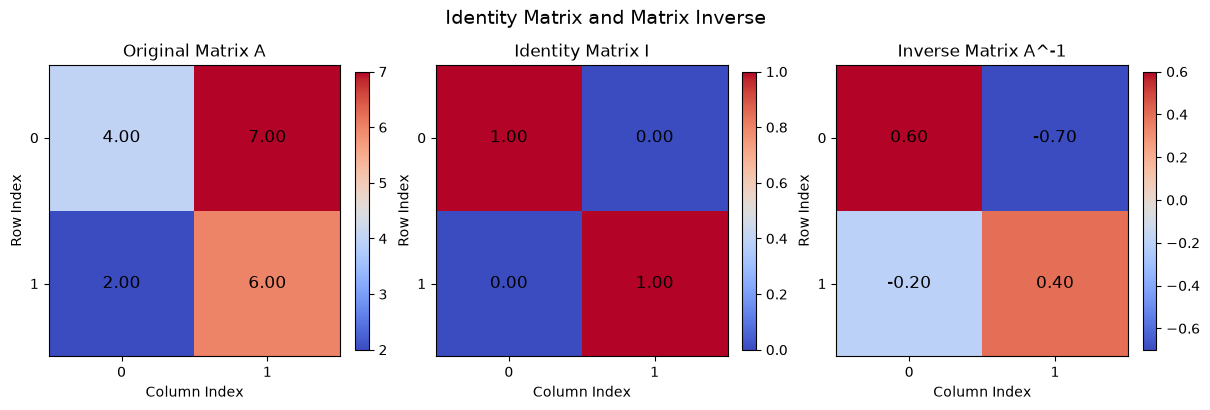

In [23]:

import matplotlib.pyplot as plt
import numpy as np

matrices = [
    A_square,
    identity_numpy,
    inverse_numpy,
]

titles = [
    "Original Matrix A",
    "Identity Matrix I",
    "Inverse Matrix A^-1",
]

fig, axes = plt.subplots(
    1, 3,
    figsize=(12, 4),
    constrained_layout=True,
)

for ax, matrix, title in zip(axes, matrices, titles):
    image = ax.imshow(matrix, cmap="coolwarm")

    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            ax.text(
                j, i,
                f"{matrix[i, j]:.2f}",
                ha="center",
                va="center",
                color="black",
                fontsize=12,
            )

    ax.set_title(title)
    ax.set_xlabel("Column Index")
    ax.set_ylabel("Row Index")
    ax.set_xticks(range(matrix.shape[1]))
    ax.set_yticks(range(matrix.shape[0]))

    fig.colorbar(image, ax=ax, shrink=0.8)

fig.suptitle("Identity Matrix and Matrix Inverse", fontsize=14)
plt.show()


In [24]:
singular_matrix = [
    [1, 2],
    [2, 4],
]

try:
    inverse_2x2_python(singular_matrix)
except ValueError as error:
    print("Correctly handled:", error)

Correctly handled: Matrix is singular and has no inverse.


## 7. Matrix Multiplication and Matrix–Vector Multiplication

### 7.1 Definition

Matrix multiplication combines the rows of the first matrix with
the columns of the second matrix.

Unlike matrix addition, matrix multiplication does not multiply
corresponding elements directly. Each output element is obtained
by calculating a dot product between a row of the first matrix
and a column of the second matrix.

### 7.2 Shape Compatibility

Suppose matrix A has shape (m, n) and matrix B has shape (n, p).

$$
A \in \mathbb{R}^{m \times n}
$$

$$
B \in \mathbb{R}^{n \times p}
$$

Their product is defined as:

$$
C = AB
$$

The resulting matrix has shape:

$$
C \in \mathbb{R}^{m \times p}
$$

The number of columns in A must equal the number of rows in B.

### 7.3 Element-wise Formula

Each element of the product matrix is calculated as:

$$
C_{ij} = \sum_{k=1}^{n} A_{ik}B_{kj}
$$

This means that we multiply corresponding elements from a row
of A and a column of B, then add all those products.

### 7.4 Worked Example

Consider:

$$
A =
\begin{bmatrix}
1 & 2 & 3 \\
4 & 5 & 6
\end{bmatrix}
$$

$$
B =
\begin{bmatrix}
7 & 8 \\
9 & 10 \\
11 & 12
\end{bmatrix}
$$

Matrix A has shape (2, 3), while B has shape (3, 2).

The multiplication is valid because the inner dimensions match.

The first element of the product is:

$$
C_{11} = 1(7) + 2(9) + 3(11) = 58
$$

The second element in the first row is:

$$
C_{12} = 1(8) + 2(10) + 3(12) = 64
$$

Applying the same procedure to the second row gives:

$$
C =
\begin{bmatrix}
58 & 64 \\
139 & 154
\end{bmatrix}
$$

The output shape is (2, 2).

### 7.5 Matrix–Vector Multiplication

A matrix can also multiply a vector.

If A has shape (m, n), and x is a vector with n components,
then the product has m components.

$$
A \in \mathbb{R}^{m \times n},
\qquad
x \in \mathbb{R}^{n}
$$

$$
y = Ax
$$

Each output component is the dot product of a row of A
with the vector x.

### 7.6 Important Properties

1. Matrix multiplication is generally not commutative:

   $$
   AB \ne BA
   $$

   The reverse product may have a different shape or may not
   be defined at all.

2. Matrix multiplication is associative:

   $$
   (AB)C = A(BC)
   $$

   Whenever the required products are defined.

3. Matrix multiplication is distributive over addition:

   $$
   A(B + C) = AB + AC
   $$

   Whenever the required operations are defined.

4. Matrix multiplication is different from element-wise multiplication.

5. Identity matrices preserve a compatible matrix under multiplication.

### 7.7 Applications in Machine Learning

Matrix multiplication is used to combine input features with model
weights, transform vectors, compute linear layers in neural networks,
and perform many numerical operations.

For a linear model, a matrix of input observations can be multiplied
by a vector of model coefficients to produce predictions.

### Learning Outcome

After this section, I should be able to derive matrix products manually,
implement matrix multiplication using pure Python, verify the result
using NumPy, understand matrix–vector multiplication, and visualize
matrix values and product shapes.

In [25]:

def multiply_matrices_python(A, B):
    """Multiply two compatible rectangular matrices."""

    # Check that both matrices are non-empty
    if not A or not B or not A[0] or not B[0]:
        raise ValueError("Matrices must be non-empty.")

    # Check that A is rectangular
    if any(len(row) != len(A[0]) for row in A):
        raise ValueError("Matrix A must be rectangular.")

    # Check that B is rectangular
    if any(len(row) != len(B[0]) for row in B):
        raise ValueError("Matrix B must be rectangular.")

    # Number of columns in A must equal rows in B
    if len(A[0]) != len(B):
        raise ValueError(
            "Columns of A must equal rows of B."
        )

    rows_A = len(A)
    cols_B = len(B[0])
    shared_dimension = len(B)

    # Calculate each output element
    result = [
        [
            sum(
                A[i][k] * B[k][j]
                for k in range(shared_dimension)
            )
            for j in range(cols_B)
        ]
        for i in range(rows_A)
    ]

    return result


# Define the matrices
A_list = [
    [1, 2, 3],
    [4, 5, 6]
]

B_list = [
    [7, 8],
    [9, 10],
    [11, 12]
]

# Perform multiplication
C_python = multiply_matrices_python(A_list, B_list)

print("Matrix A:", A_list)
print("Matrix B:", B_list)
print("Product AB:", C_python)
print("Output shape:", (len(C_python), len(C_python[0])))


Matrix A: [[1, 2, 3], [4, 5, 6]]
Matrix B: [[7, 8], [9, 10], [11, 12]]
Product AB: [[58, 64], [139, 154]]
Output shape: (2, 2)


In [26]:

import numpy as np

A_np = np.array(A_list)
B_np = np.array(B_list)

# @ performs matrix multiplication
C_numpy = A_np @ B_np

print("Shape of A:", A_np.shape)
print("Shape of B:", B_np.shape)
print("\nNumPy product AB:\n", C_numpy)
print("Shape of AB:", C_numpy.shape)

print(
    "\nPython and NumPy results match:",
    np.array_equal(C_python, C_numpy)
)


Shape of A: (2, 3)
Shape of B: (3, 2)

NumPy product AB:
 [[ 58  64]
 [139 154]]
Shape of AB: (2, 2)

Python and NumPy results match: True


In [27]:

def multiply_matrix_vector_python(A, x):
    """Multiply a rectangular matrix by a compatible vector."""

    if not A or not A[0]:
        raise ValueError("Matrix must be non-empty.")

    if any(len(row) != len(A[0]) for row in A):
        raise ValueError("Matrix must be rectangular.")

    if len(A[0]) != len(x):
        raise ValueError(
            "Matrix columns must equal vector length."
        )

    return [
        sum(element * value for element, value in zip(row, x))
        for row in A
    ]


x_list = [1, 2, 1]

y_python = multiply_matrix_vector_python(A_list, x_list)

print("Input vector:", x_list)
print("Matrix-vector product:", y_python)


Input vector: [1, 2, 1]
Matrix-vector product: [8, 20]


In [28]:
x_np = np.array(x_list)
y_numpy = A_np @ x_np

print("NumPy result:", y_numpy)
print("Output shape:", y_numpy.shape)
print(
    "Results match:",
    np.array_equal(y_python, y_numpy)
)

NumPy result: [ 8 20]
Output shape: (2,)
Results match: True


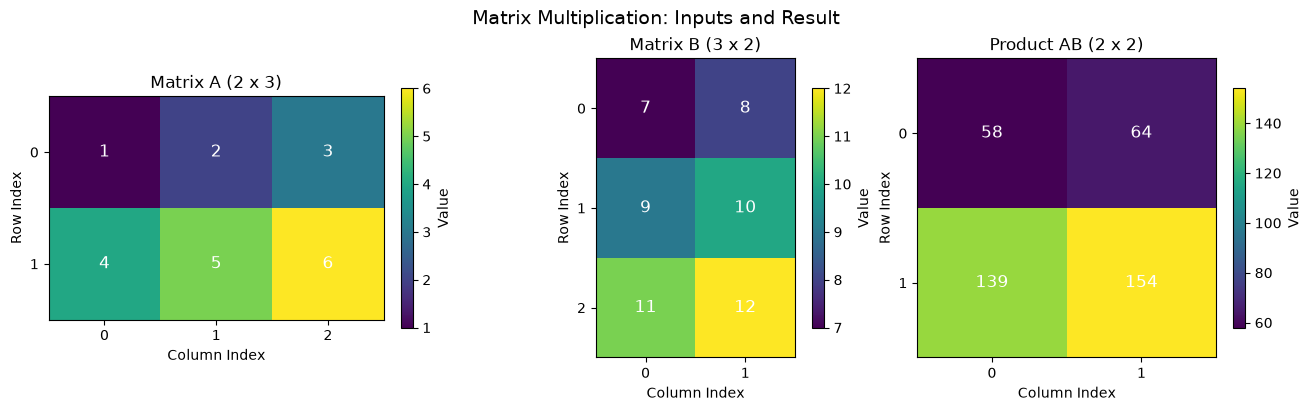

In [29]:

import matplotlib.pyplot as plt
import numpy as np

matrices = [A_np, B_np, C_numpy]
titles = ["Matrix A (2 x 3)", "Matrix B (3 x 2)", "Product AB (2 x 2)"]

fig, axes = plt.subplots(
    1, 3,
    figsize=(13, 4),
    constrained_layout=True
)

for ax, M, title in zip(axes, matrices, titles):
    image = ax.imshow(M, cmap="viridis")

    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(
                j, i,
                str(M[i, j]),
                ha="center",
                va="center",
                color="white",
                fontsize=12
            )

    ax.set_title(title)
    ax.set_xlabel("Column Index")
    ax.set_ylabel("Row Index")
    ax.set_xticks(range(M.shape[1]))
    ax.set_yticks(range(M.shape[0]))

    fig.colorbar(image, ax=ax, shrink=0.8, label="Value")

fig.suptitle("Matrix Multiplication: Inputs and Result", fontsize=14)
plt.show()


In [30]:
try:
    multiply_matrices_python(
        [[1, 2, 3], [4, 5, 6]],
        [[1, 2], [3, 4]]
    )
except ValueError as error:
    print("Correctly rejected:", error)

Correctly rejected: Columns of A must equal rows of B.


## 8. Geometric Transformations with Matrices

### 8.1 Introduction

A matrix can represent a linear transformation that changes the
position of a vector in a coordinate space.

In two dimensions, a transformation can scale, rotate, or reflect
points. Applying the same transformation matrix to multiple points
allows us to transform an entire geometric shape.

### 8.2 Scaling Transformation

Scaling changes the coordinates of a point by multiplying each
coordinate by a scale factor.

For horizontal scale factor sx and vertical scale factor sy:

$$
S =
\begin{bmatrix}
s_x & 0 \\
0 & s_y
\end{bmatrix}
$$

For a column vector:

$$
\mathbf{p} =
\begin{bmatrix}
x \\
y
\end{bmatrix}
$$

The transformed point is:

$$
\mathbf{p}' = S\mathbf{p}
=
\begin{bmatrix}
s_xx \\
s_yy
\end{bmatrix}
$$

When both scale factors are greater than one, the corresponding
coordinates increase in magnitude. A factor between zero and one
shrinks coordinates along that axis.

### 8.3 Rotation Transformation

A counterclockwise rotation by angle theta about the origin is
represented by:

$$
R(\theta) =
\begin{bmatrix}
\cos\theta & -\sin\theta \\
\sin\theta & \cos\theta
\end{bmatrix}
$$

The transformed point is:

$$
\mathbf{p}' = R(\theta)\mathbf{p}
$$

For a 90-degree counterclockwise rotation:

$$
R(90^\circ) =
\begin{bmatrix}
0 & -1 \\
1 & 0
\end{bmatrix}
$$

Therefore, the point (1, 0) is transformed into (0, 1).

### 8.4 Important Properties

1. Scaling and rotation matrices are both examples of linear
   transformations.

2. Linear transformations preserve vector addition and scalar
   multiplication.

3. Rotation preserves vector lengths and angles between vectors.

4. A general scaling transformation can change vector lengths
   and the area of a shape.

5. A linear transformation leaves the origin fixed.

6. Rotation formulas use radians in NumPy's trigonometric
   functions. Degrees must be converted to radians before use.

### 8.5 Matrix Shapes and Point Representation

A 2 x 2 transformation matrix multiplies a two-component column
vector and returns another two-component vector.

When multiple points are stored as rows in a NumPy array with
shape (n, 2), the equivalent transformation is performed as:

$$
P' = PR^T
$$

for a rotation matrix R, or:

$$
P' = PS^T
$$

for a scaling matrix S.

The transpose is needed because the points are stored as rows
rather than as individual column vectors.

### 8.6 Applications in Machine Learning and AI

Matrix transformations are used in computer graphics, image
processing, coordinate transformations, data representation,
and neural-network computations.

Understanding these operations helps build intuition for how
matrices transform numerical data in higher-dimensional spaces.

### Learning Outcome

After this section, I should be able to construct scaling and
rotation matrices, transform points using matrix multiplication,
verify the results with NumPy, and visualize original and
transformed geometric shapes using Matplotlib.

In [31]:

import numpy as np

# Scaling factors
sx = 1.5
sy = 0.75

scaling_matrix = np.array([
    [sx, 0.0],
    [0.0, sy]
])

# Rotation angle
angle_degrees = 35
angle_radians = np.deg2rad(angle_degrees)

rotation_matrix = np.array([
    [np.cos(angle_radians), -np.sin(angle_radians)],
    [np.sin(angle_radians),  np.cos(angle_radians)]
])

# A single point represented as a 2-component vector
point = np.array([2.0, 1.0])

scaled_point = scaling_matrix @ point
rotated_point = rotation_matrix @ point

print("Scaling matrix:\n", scaling_matrix)
print("\nRotation matrix:\n", rotation_matrix)

print("\nOriginal point:", point)
print("Scaled point:", scaled_point)
print("Rotated point:", rotated_point)


Scaling matrix:
 [[1.5  0.  ]
 [0.   0.75]]

Rotation matrix:
 [[ 0.81915204 -0.57357644]
 [ 0.57357644  0.81915204]]

Original point: [2. 1.]
Scaled point: [3.   0.75]
Rotated point: [1.06472765 1.96630492]


In [32]:

# Triangle vertices stored as rows
original_points = np.array([
    [0.0, 0.0],
    [2.0, 0.0],
    [1.0, 1.5],
    [0.0, 0.0]  # Repeat the first point to close the triangle
])

# Apply transformations to all points
scaled_points = original_points @ scaling_matrix.T
rotated_points = original_points @ rotation_matrix.T

print("Original points:\n", original_points)
print("\nScaled points:\n", scaled_points)
print("\nRotated points:\n", rotated_points)

print("\nOriginal shape:", original_points.shape)
print("Scaled shape:", scaled_points.shape)
print("Rotated shape:", rotated_points.shape)


Original points:
 [[0.  0. ]
 [2.  0. ]
 [1.  1.5]
 [0.  0. ]]

Scaled points:
 [[0.    0.   ]
 [3.    0.   ]
 [1.5   1.125]
 [0.    0.   ]]

Rotated points:
 [[ 0.          0.        ]
 [ 1.63830409  1.14715287]
 [-0.04121261  1.8023045 ]
 [ 0.          0.        ]]

Original shape: (4, 2)
Scaled shape: (4, 2)
Rotated shape: (4, 2)


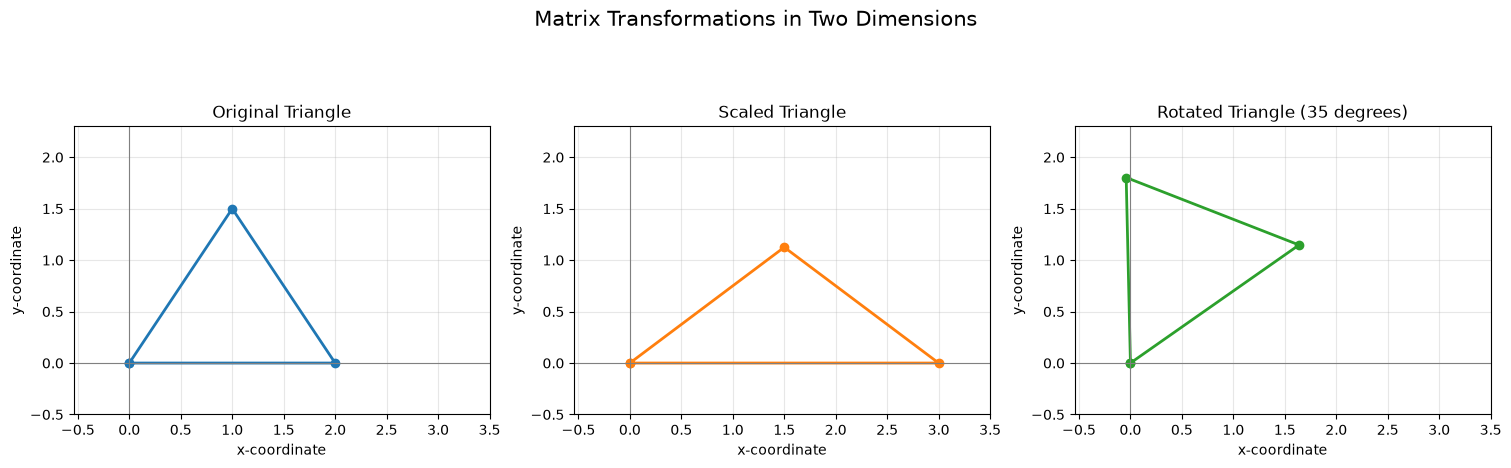

In [33]:

import matplotlib.pyplot as plt
import numpy as np

point_sets = [
    original_points,
    scaled_points,
    rotated_points
]

titles = [
    "Original Triangle",
    "Scaled Triangle",
    "Rotated Triangle (35 degrees)"
]

colors = ["tab:blue", "tab:orange", "tab:green"]

# Find common axis limits for fair comparison
all_points = np.vstack(point_sets)

padding = 0.5
x_min = all_points[:, 0].min() - padding
x_max = all_points[:, 0].max() + padding
y_min = all_points[:, 1].min() - padding
y_max = all_points[:, 1].max() + padding

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 5),
    constrained_layout=True
)

for ax, points, title, color in zip(
    axes, point_sets, titles, colors
):
    ax.plot(
        points[:, 0],
        points[:, 1],
        marker="o",
        linewidth=2,
        color=color
    )

    # Show the origin and coordinate axes
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.axvline(0, color="gray", linewidth=0.8)

    ax.set_title(title)
    ax.set_xlabel("x-coordinate")
    ax.set_ylabel("y-coordinate")

    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_aspect("equal", adjustable="box")
    ax.grid(True, alpha=0.3)

fig.suptitle(
    "Matrix Transformations in Two Dimensions",
    fontsize=15
)

plt.show()


In [34]:

# A pure rotation should preserve distances from the origin
original_length = np.linalg.norm(point)
rotated_length = np.linalg.norm(rotated_point)

# Scaling determinant gives the signed area scale factor
area_scale_factor = np.linalg.det(scaling_matrix)

# Rotation determinant should be approximately 1
rotation_determinant = np.linalg.det(rotation_matrix)

print("Original point length:", original_length)
print("Rotated point length:", rotated_length)

print(
    "Rotation preserves length:",
    np.isclose(original_length, rotated_length)
)

print("Scaling area factor:", area_scale_factor)
print("Rotation determinant:", rotation_determinant)


Original point length: 2.23606797749979
Rotated point length: 2.23606797749979
Rotation preserves length: True
Scaling area factor: 1.125
Rotation determinant: 1.0


## 9. Determinant and Matrix Invertibility

### 9.1 Definition

The determinant is a scalar value associated with a square matrix.
It provides useful information about the matrix's invertibility
and the effect of its linear transformation on area or volume.

The determinant of a matrix A is written as:

$$
\det(A) \quad \text{or} \quad |A|
$$

A determinant is defined for square matrices, such as 2 x 2
or 3 x 3 matrices.

### 9.2 Determinant of a 2 x 2 Matrix

For the matrix:

$$
A =
\begin{bmatrix}
a & b \\
c & d
\end{bmatrix}
$$

The determinant is:

$$
\det(A) = ad - bc
$$

### 9.3 Worked Example

Consider:

$$
A =
\begin{bmatrix}
2 & 1 \\
1 & 2
\end{bmatrix}
$$

Its determinant is:

$$
\det(A) = (2)(2) - (1)(1) = 3
$$

Since the determinant is non-zero, A is invertible.

### 9.4 Determinant and Invertibility

For a square matrix A:

- If det(A) is non-zero, A is invertible.
- If det(A) is zero, A is singular and has no ordinary inverse.

$$
\det(A) \ne 0
\quad \Longleftrightarrow \quad
A^{-1} \text{ exists}
$$

A determinant of zero means that the transformation collapses
at least one dimension, so the original information cannot
be uniquely recovered through an inverse transformation.

### 9.5 Geometric Interpretation

For a 2D linear transformation, the absolute value of the
determinant gives the area-scaling factor.

$$
\text{Area scale factor} = |\det(A)|
$$

If the absolute determinant is 3, a region's area becomes
three times its original area.

The sign also carries information: a negative determinant
indicates an orientation reversal, whereas a positive determinant
preserves orientation.

### 9.6 Important Notes

1. Determinants are defined only for square matrices.
2. The determinant is a scalar, not a matrix.
3. A non-zero determinant indicates invertibility.
4. Determinants close to zero can require careful numerical
   interpretation in floating-point computations.
5. The determinant alone does not measure every aspect of
   numerical stability.

### 9.7 Applications in Machine Learning

Determinants appear in multivariate probability distributions,
coordinate transformations, covariance calculations, and
linear algebra derivations.

In numerical applications, determinant calculations should be
interpreted carefully, especially for large or poorly conditioned
matrices.

### Learning Outcome

After this section, I should be able to calculate the determinant
of a 2 x 2 matrix, verify it with NumPy, connect the determinant
to invertibility, and visualize its geometric area-scaling effect.

In [1]:

def determinant_2x2_python(matrix):
    """Calculate the determinant of a 2 x 2 matrix."""

    if len(matrix) != 2 or any(len(row) != 2 for row in matrix):
        raise ValueError("Matrix must have shape (2, 2).")

    a, b = matrix[0]
    c, d = matrix[1]

    return a * d - b * c


# Worked example
A_list = [
    [2, 1],
    [1, 2]
]

det_python = determinant_2x2_python(A_list)

print("Matrix A:", A_list)
print("Determinant:", det_python)
print("Is invertible:", det_python != 0)


Matrix A: [[2, 1], [1, 2]]
Determinant: 3
Is invertible: True


In [2]:

import numpy as np

A_np = np.array(A_list, dtype=float)

det_numpy = np.linalg.det(A_np)

print("Determinant using NumPy:", det_numpy)
print(
    "Python and NumPy results match:",
    np.isclose(det_python, det_numpy)
)

inverse_np = np.linalg.inv(A_np)

print("\nInverse of A:\n", inverse_np)

print(
    "\nA multiplied by its inverse equals identity:",
    np.allclose(A_np @ inverse_np, np.eye(2))
)


Determinant using NumPy: 2.9999999999999996
Python and NumPy results match: True

Inverse of A:
 [[ 0.66666667 -0.33333333]
 [-0.33333333  0.66666667]]

A multiplied by its inverse equals identity: True


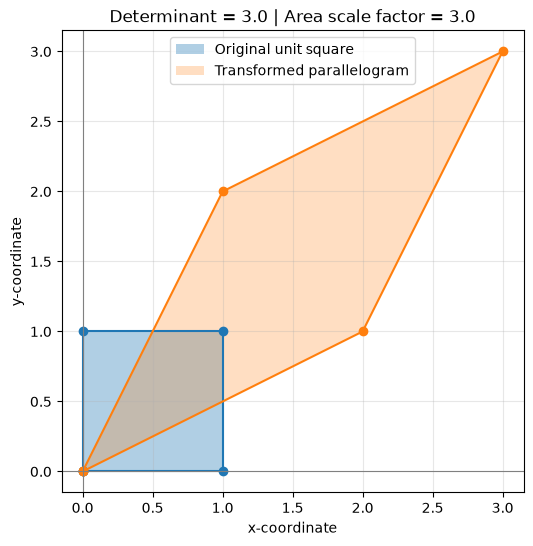

In [3]:

import matplotlib.pyplot as plt
import numpy as np

A_np = np.array([
    [2, 1],
    [1, 2]
], dtype=float)

determinant = np.linalg.det(A_np)

# Vertices of the unit square, repeating the first point to close it
square = np.array([
    [0, 0],
    [1, 0],
    [1, 1],
    [0, 1],
    [0, 0]
], dtype=float)

# Points are stored as rows, so multiply by A.T
transformed = square @ A_np.T

fig, ax = plt.subplots(figsize=(8, 6))

ax.fill(
    square[:, 0], square[:, 1],
    alpha=0.35,
    label="Original unit square"
)

ax.plot(
    square[:, 0], square[:, 1],
    marker="o"
)

ax.fill(
    transformed[:, 0], transformed[:, 1],
    alpha=0.25,
    label="Transformed parallelogram"
)

ax.plot(
    transformed[:, 0], transformed[:, 1],
    marker="o"
)

ax.axhline(0, color="gray", linewidth=0.8)
ax.axvline(0, color="gray", linewidth=0.8)

ax.set_title(
    f"Determinant = {determinant:.1f} | "
    f"Area scale factor = {abs(determinant):.1f}"
)

ax.set_xlabel("x-coordinate")
ax.set_ylabel("y-coordinate")

ax.set_aspect("equal", adjustable="box")
ax.grid(True, alpha=0.3)
ax.legend()

plt.show()


In [4]:
singular_matrix = [
    [1, 2],
    [2, 4]
]

det_singular = determinant_2x2_python(singular_matrix)

print("Singular matrix determinant:", det_singular)
print("Is invertible:", not np.isclose(det_singular, 0.0))

Singular matrix determinant: 0
Is invertible: False
